# Task 2: KDEF dataset study

**Pre-Requisite**:
- `data/fer/fer2013_train.csv` and `data/fer/fer2013_test.csv`
- `figures/task1_validation_results.csv` and `figures/task1_test_results.csv` from task 1
- `models/fer_hog_svm.pkl` and `data/fer/features/hog_test.npy` from task 1

We take the best FER2013 features from Task 1 (HOG), retrain Logistic Regression, SVM and Random Forest on frontal KDEF images, and compare the results with FER2013.

## Variable Initialization

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import pickle

# Find the repository root from wherever Jupyter starts (the notebook's own folder).
ROOT = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / "auxFiles/kdef_subject_split.pkl").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Repository root not found")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.preprocess import preprocess_kdef_image

## Variables for KDEF dataset
KDEF_DIR = ROOT / "data/kdef/KDEF"
EMOTIONS = {
    "AF": "afraid",
    "AN": "angry",
    "DI": "disgust",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sad",
    "SU": "surprise",
    
}

POSES = {
    "FL": "full_left",
    "HL": "half_left",
    "S":  "straight",
    "HR": "half_right",
    "FR": "full_right",
}

EMOTION_LABELS = EMOTIONS.values()

## Variables for FER dataset
FER_DIR = Path(ROOT / "data/fer")
FER_EMOTION_DICT = {
    0:'0: Angry',
    1:'1: Disgust',
    2:'2: Fear',
    3:'3: Happy',
    4:'4: Sad',
    5:'5: Surprise',
    6:'6: Neutral'
}

FER_EMOTION_LABELS = [emot.split(": ")[1] for emot in FER_EMOTION_DICT.values()]

MODEL_DIR = Path(ROOT / "models")


## Load KDEF and split by subject
List all KDEF images, keep only the frontal (straight) pose, and split them with the provided subject split: 56 people for training and 14 for testing.

In [2]:
with open(ROOT / "auxFiles/kdef_subject_split.pkl", "rb") as subj_split:
    split = pickle.load(subj_split)
    train_subjects = split['train_subjects']
    test_subjects = split['test_subjects']

def load_kdef_into_dataframe():
    records = []
    for img_path in KDEF_DIR.rglob("*.JPG"):
        stem = img_path.stem
        acquisition = stem[0]   # A or B
        subject = stem[1:4]     # F01, M12, ...
        found = False

        for emotion_code in EMOTIONS:

            if stem[4:].startswith(emotion_code):

                pose_code = stem[4+len(emotion_code):]

                if pose_code not in POSES:
                    continue

                records.append({
                    "path": str(img_path),
                    "acquisition": acquisition,
                    "subject": subject,
                    "emotion": EMOTIONS[emotion_code],
                    "pose": POSES[pose_code],
                })


                found = True
                break

        if not found:
            print("Skipping:", stem)
    df = pd.DataFrame(records)
    return df

df = load_kdef_into_dataframe()

Skipping: AM31H
Skipping: AF31V


In [3]:
print(df)

                                                   path acquisition subject  \
0     /Users/henriquedasilvacouto/workspace/TUe-Mast...           B     M20   
1     /Users/henriquedasilvacouto/workspace/TUe-Mast...           B     M20   
2     /Users/henriquedasilvacouto/workspace/TUe-Mast...           B     M20   
3     /Users/henriquedasilvacouto/workspace/TUe-Mast...           B     M20   
4     /Users/henriquedasilvacouto/workspace/TUe-Mast...           B     M20   
...                                                 ...         ...     ...   
4893  /Users/henriquedasilvacouto/workspace/TUe-Mast...           B     M06   
4894  /Users/henriquedasilvacouto/workspace/TUe-Mast...           B     M06   
4895  /Users/henriquedasilvacouto/workspace/TUe-Mast...           B     M06   
4896  /Users/henriquedasilvacouto/workspace/TUe-Mast...           B     M06   
4897  /Users/henriquedasilvacouto/workspace/TUe-Mast...           B     M06   

       emotion        pose  
0     surprise    stra

In [4]:
train_df = df[
    (df["subject"].isin(train_subjects))
    & (df["pose"] == "straight")
]

test_df = df[
    (df["subject"].isin(test_subjects))
    & (df["pose"] == "straight")
]

### Check the split
Images per emotion in each split, and a check that no person is in both.

,train,test
emotion,,
afraid,112,28
angry,112,28
disgust,112,28
happy,112,28
neutral,112,28
sad,112,28
surprise,112,28


,subjects,images
train,56,784
test,14,196


Subjects in both train and test: NIL


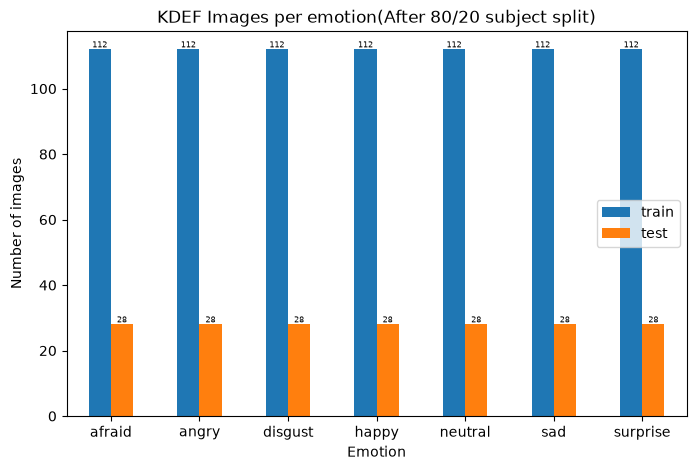

In [5]:
import matplotlib.pyplot as plt

split_counts = pd.DataFrame({
    "train": train_df["emotion"].value_counts(),
    "test":  test_df["emotion"].value_counts(),
}).reindex(EMOTION_LABELS)
display(split_counts)


subject_summary = pd.DataFrame({
    "subjects":  [train_df["subject"].nunique(), test_df["subject"].nunique()],
    "images":    [len(train_df), len(test_df)]
}, index=["train", "test"])
display(subject_summary)

overlap = set(train_df["subject"]) & set(test_df["subject"])
assert not overlap, f"Subjects in both train and test: {overlap}"
print("Subjects in both train and test: NIL")

ax = split_counts.plot.bar(figsize=(8, 5))
ax.set_title("KDEF Images per emotion(After 80/20 subject split)")
ax.set_ylabel("Number of images")
ax.set_xlabel("Emotion")
for container in ax.containers:
    ax.bar_label(container, fontsize=6)
plt.xticks(rotation=0)
plt.savefig(ROOT / "figures/task2_kdef_class_distribution.png", dpi=150)
plt.show()

## Preprocess KDEF into the FER format
We use the preprocessing baseline provided with the assignment (`preprocess_kdef_image` in `scripts/preprocess.py`): face detection, 20% margin around the face, grayscale, resize to 48x48 and scale to values between 0 and 1.

In [6]:
## FROM provided python notebook
X_train = []
y_train = []
X_train_subject_list = []
for _, row in train_df.iterrows():

    try:
        img = preprocess_kdef_image(row["path"])

        X_train.append(img)
        y_train.append(row["emotion"])
        X_train_subject_list.append(row['subject'])

    except Exception as e:
        print(e)

X_train = np.array(X_train)
y_train = np.array(y_train)

X_test = []
y_test = []

for _, row in test_df.iterrows():

    try:
        img = preprocess_kdef_image(row["path"])

        X_test.append(img)
        y_test.append(row["emotion"])

    except Exception as e:
        print(e)

X_test = np.array(X_test)
y_test = np.array(y_test)

### Mean face per emotion: KDEF vs FER2013

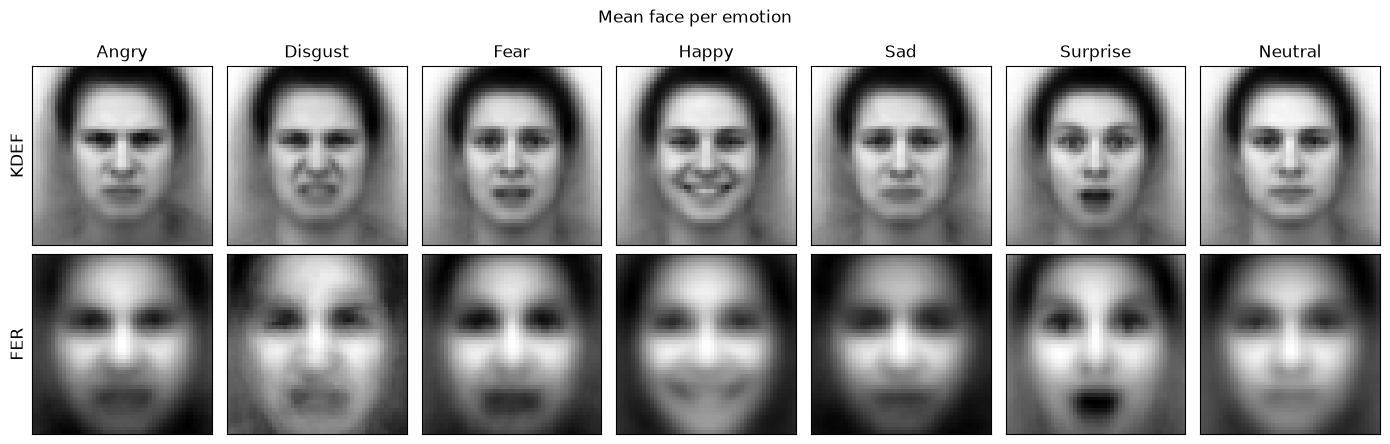

In [7]:
# FER name (index = FER label) -> KDEF label
FER_TO_KDEF_LABEL = {"Angry": "angry", "Disgust": "disgust", "Fear": "afraid", "Happy": "happy",
                     "Sad": "sad", "Surprise": "surprise", "Neutral": "neutral"}

# KDEF: reload the raw 48x48 training images (X_train now holds HOG features)
kdef_imgs = X_train.copy()
kdef_labels = y_train.copy()

# FER: raw 48x48 training images
fer_train = pd.read_csv(ROOT / "data/fer/fer2013_train.csv")
fer_imgs = np.stack([np.array(p.split(), dtype=np.uint8).reshape(48, 48) for p in fer_train["pixels"]])
fer_labels = fer_train["emotion"].values

fig, axes = plt.subplots(2, 7, figsize=(14, 4.6))
for k, fer_name in enumerate(FER_EMOTION_LABELS):
    kdef_name = FER_TO_KDEF_LABEL[fer_name]
    axes[0, k].imshow(kdef_imgs[kdef_labels == kdef_name].mean(axis=0), cmap="gray")
    axes[1, k].imshow(fer_imgs[fer_labels == k].mean(axis=0), cmap="gray")
    axes[0, k].set_title(fer_name)
    for ax in axes[:, k]:
        ax.set_xticks([])
        ax.set_yticks([])
axes[0, 0].set_ylabel("KDEF", fontsize=12)
axes[1, 0].set_ylabel("FER", fontsize=12)
plt.suptitle("Mean face per emotion")
plt.tight_layout(); 
plt.savefig(ROOT / "figures/task2_mean_faces_kdef_vs_fer.png", dpi=150); plt.show()


## HOG feature extraction
The same HOG settings as in Task 1, which gives 900 features per image.

In [8]:
from scripts.feature_extraction import extract_hog_kdef

X_train = extract_hog_kdef(X_train)
X_test = extract_hog_kdef(X_test)

## Hyperparameter tuning
Grid search with 5-fold cross-validation on the training subjects only. The folds are split by subject, and the best setting is chosen by macro-F1. The test subjects are not used here.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 10

def init_model_pipelines():
    pipelines = {
        "LogisticRegression": Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
        "SVM": Pipeline([("scaler", StandardScaler()),("model", SVC(random_state=RANDOM_STATE))]),
        "RandomForest": Pipeline([("model", RandomForestClassifier(random_state=RANDOM_STATE))]),
    }

    return pipelines



In [10]:
from sklearn.preprocessing import MinMaxScaler, PowerTransformer, RobustScaler

def init_model_hyperparameters():
    svm_scalers = [StandardScaler(), RobustScaler(), PowerTransformer()]
    svm_C = [0.01, 0.1, 1.0, 10.0]

    hyperparameters = {
        "LogisticRegression": {
            "scaler": ["passthrough", StandardScaler(), RobustScaler(), MinMaxScaler(), PowerTransformer()],
            "model__C": [0.01, 0.1, 1.0, 10.0]
        },
        "RandomForest": {
            "model__n_estimators": [100, 200],
            "model__max_depth": [3, 5, 8, 10, 15, 20, None],
            "model__min_samples_leaf": [1, 2, 5, 10, 20, 50]
        },
        "SVM": [
            {   
                "scaler": svm_scalers,
                "model__kernel": ["linear"],
                "model__C": svm_C,
            },
            {   
                "scaler": svm_scalers,
                "model__kernel": ["rbf"],
                "model__C": svm_C,
                "model__gamma": [0.01, 0.001, 0.0001, "auto"],
            },
            {   
                "scaler": svm_scalers,
                "model__kernel": ["poly"],
                "model__C": svm_C,
                "model__degree": [2, 3, 4],
            },
        ],
    }
    return hyperparameters


In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import GroupKFold, cross_validate

def find_best_model():
    NUM_SPLITS = 5
    RANDOM_STATE = 10
    group_k_fold = GroupKFold(n_splits = NUM_SPLITS)
    SCORING = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy", "macro_f1": "f1_macro"}

    best_rows = []
    evaluation_metric = "macro_f1"
    model_pipelines = init_model_pipelines()
    model_hyperparameters = init_model_hyperparameters()

    for model_name in model_pipelines:
        print('---------------------------------------------------')
        print(f'Running the GridSearchCV for {model_name}')
        print('---------------------------------------------------')

        pipeline = model_pipelines[model_name]
        hyperparameter = model_hyperparameters[model_name]

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=hyperparameter,
            scoring=SCORING,
            refit=evaluation_metric,
            cv=group_k_fold,
            n_jobs=-1,
            return_train_score=True,
            verbose=1
            )
        
        search.fit(X_train, y_train, groups=X_train_subject_list)

        # Cross-validation metrics of the best hyperparameter configuration (selected by evaluation_metric)
        best_idx = search.best_index_
        row = {"model": model_name, "params": search.best_params_, "estimator": search.best_estimator_}

        for score in SCORING:
            row[f"mean_test_{score}"] = search.cv_results_[f"mean_test_{score}"][best_idx]
                
        best_rows.append(row)

    best_results_df = pd.DataFrame(best_rows)
    display(best_results_df)

    return best_results_df

### Load the cached model/results, or find the best model

In [12]:
KDEF_MODEL_FILE_PATH = MODEL_DIR / "task2_kdef_best_model_configs.pkl"

if not Path(KDEF_MODEL_FILE_PATH).exists():
    best_results_df = find_best_model()
    best_results_df.to_pickle(KDEF_MODEL_FILE_PATH)
    print(f'Saved best models to {KDEF_MODEL_FILE_PATH}')
else:
    best_results_df = pd.read_pickle(KDEF_MODEL_FILE_PATH)
    print(f'Loaded best models from {KDEF_MODEL_FILE_PATH}')

Loaded best models from /Users/henriquedasilvacouto/workspace/TUe-Master_AI_and_ES/Masters-database/5ARE0_2026-GS1/Assignment_2/ml-emotionalrecognition/models/task2_kdef_best_model_configs.pkl


In [13]:
best_results_df

,model,params,estimator,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_macro_f1
0,LogisticRegression,"{'model__C': 0.01, 'scaler': PowerTransformer()}","(PowerTransformer(), LogisticRegression(C=0.01...",0.674026,0.674026,0.669255
1,SVM,"{'model__C': 10.0, 'model__gamma': 0.0001, 'mo...","(PowerTransformer(), SVC(C=10.0, gamma=0.0001,...",0.686039,0.686039,0.678805
2,RandomForest,"{'model__max_depth': 10, 'model__min_samples_l...","((DecisionTreeClassifier(max_depth=10, max_fea...",0.628247,0.628247,0.610818


## Comparison with FER2013(from Task 1)

In [14]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

def compute_scores(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }

# Mapping between notebook 1 artifacts
NB1_MODEL_CONV = {"LogReg": "LogisticRegression", "SVM": "SVM", "RF": "RandomForest"}

rows = []  


fer_val = pd.read_csv(ROOT / "figures/task1_validation_results.csv")
fer_val = fer_val[fer_val["features"] == "HOG"]

for _, row in fer_val.iterrows():
    rows.append({
        "Dataset": "FER",
        "Phase": "Validation",
        "Classifier": NB1_MODEL_CONV[row["classifier"]],
        "accuracy": row["accuracy"],
        "balanced_accuracy": row["balanced_accuracy"],
        "macro_f1": row["macro_f1"],
    })


fer_test = pd.read_csv(ROOT / "figures/task1_test_results.csv")
# The test file names each model as "<features>+<classifier>", e.g. "HOG+SVM".
fer_test = fer_test[fer_test["model"].str.startswith("HOG+")]

for _, row in fer_test.iterrows():
    rows.append({
        "Dataset": "FER",
        "Phase": "Test",
        "Classifier": NB1_MODEL_CONV[row["model"].split("+")[1]],
        "accuracy": row["accuracy"],
        "balanced_accuracy": row["balanced_accuracy"],
        "macro_f1": row["macro_f1"],
    })

for _, row in best_results_df.iterrows():
    rows.append({
        "Dataset": "KDEF",
        "Phase": "Validation",
        "Classifier": row["model"],
        "accuracy": row["mean_test_accuracy"],
        "balanced_accuracy": row["mean_test_balanced_accuracy"],
        "macro_f1": row["mean_test_macro_f1"],
    })

    y_pred = row["estimator"].predict(X_test)
    scores = compute_scores(y_test, y_pred)
    rows.append({"Dataset": "KDEF", "Phase": "Test", "Classifier": row["model"], **scores})


comparison = pd.DataFrame(rows)
comparison.to_csv(ROOT / "figures/task2_kdef_vs_fer_results.csv", index=False)
display(comparison.round(3))


,Dataset,Phase,Classifier,accuracy,balanced_accuracy,macro_f1
0,FER,Validation,LogisticRegression,0.435,0.397,0.395
1,FER,Validation,SVM,0.542,0.482,0.505
2,FER,Validation,RandomForest,0.482,0.414,0.440
3,FER,Test,LogisticRegression,0.438,0.376,0.378
4,FER,Test,SVM,0.575,0.550,0.568
5,KDEF,Validation,LogisticRegression,0.674,0.674,0.669
6,KDEF,Test,LogisticRegression,0.577,0.577,0.581
7,KDEF,Validation,SVM,0.686,0.686,0.679
8,KDEF,Test,SVM,0.602,0.602,0.604
9,KDEF,Validation,RandomForest,0.628,0.628,0.611


### Model ranking

In [15]:
ranking = comparison.pivot(index="Classifier", columns=["Dataset", "Phase"], values="macro_f1")
display(ranking.round(3))


Dataset                   FER              KDEF       
Phase              Validation   Test Validation   Test
Classifier                                            
LogisticRegression      0.395  0.378      0.669  0.581
RandomForest            0.440    NaN      0.611  0.614
SVM                     0.505  0.568      0.679  0.604

## Per-emotion results and confusion matrices

===== LogisticRegression (KDEF test) =====
              precision    recall  f1-score   support

       Angry      0.600     0.429     0.500        28
     Disgust      0.706     0.429     0.533        28
        Fear      0.341     0.500     0.406        28
       Happy      0.958     0.821     0.885        28
         Sad      0.519     0.500     0.509        28
    Surprise      0.556     0.714     0.625        28
     Neutral      0.581     0.643     0.610        28

    accuracy                          0.577       196
   macro avg      0.609     0.577     0.581       196
weighted avg      0.609     0.577     0.581       196

===== SVM (KDEF test) =====
              precision    recall  f1-score   support

       Angry      0.600     0.429     0.500        28
     Disgust      0.762     0.571     0.653        28
        Fear      0.312     0.357     0.333        28
       Happy      0.962     0.893     0.926        28
         Sad      0.556     0.536     0.545        28
    Sur

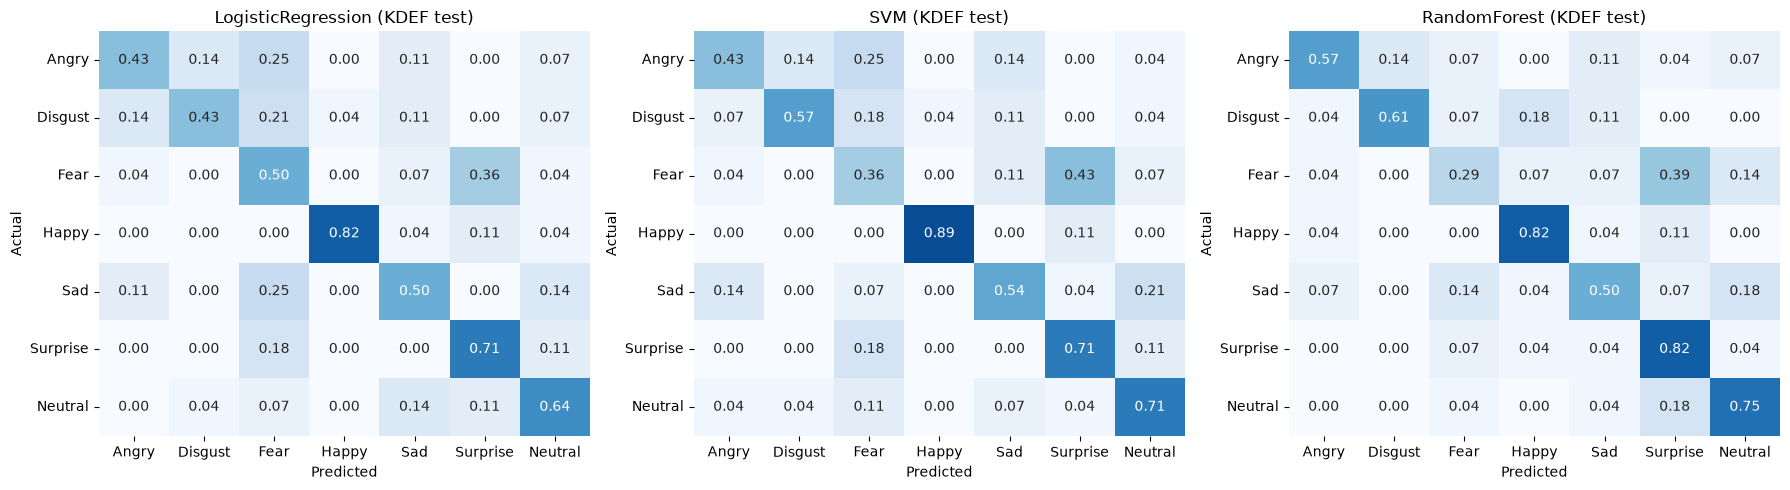

,KDEF test: LogisticRegression,KDEF test: SVM,KDEF test: RandomForest,FER test: SVM
Angry,0.500,0.500,0.653,0.438
Disgust,0.533,0.653,0.694,0.622
Fear,0.406,0.333,0.340,0.458
Happy,0.885,0.926,0.767,0.754
Sad,0.509,0.545,0.528,0.433
Surprise,0.625,0.615,0.630,0.728
Neutral,0.610,0.656,0.689,0.545


In [16]:
import joblib
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

KDEF_ORDER = [FER_TO_KDEF_LABEL[name] for name in FER_EMOTION_LABELS]   # KDEF names in FER order

# KDEF: confusion matrix + per-emotion F1 for each best model (test subjects)
fig, axes = plt.subplots(1, len(best_results_df), figsize=(6 * len(best_results_df), 5))
per_emotion_f1 = {}
for ax, (_, row) in zip(axes, best_results_df.iterrows()):
    y_pred = row["estimator"].predict(X_test)
    print(f"===== {row['model']} (KDEF test) =====")
    print(classification_report(y_test, y_pred, labels=KDEF_ORDER, target_names=FER_EMOTION_LABELS, digits=3))
    per_emotion_f1[f"KDEF test: {row['model']}"] = f1_score(y_test, y_pred, labels=KDEF_ORDER, average=None)

    cm = confusion_matrix(y_test, y_pred, labels=KDEF_ORDER, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=FER_EMOTION_LABELS, yticklabels=FER_EMOTION_LABELS, ax=ax)
    ax.set_title(f"{row['model']} (KDEF test)")
    ax.set_ylabel("Actual")
    ax.set_xlabel("Predicted")
    
plt.tight_layout(); plt.savefig(ROOT / "figures/task2_kdef_confusion_test.png", dpi=150); plt.show()

# FER: per-emotion F1 of the final Task 1 model (HOG + SVM) on the FER test split
fer_model = joblib.load(MODEL_DIR / "fer_hog_svm.pkl")
X_fer_test = np.load(FER_DIR / "features/hog_test.npy")
y_fer_test = pd.read_csv(FER_DIR / "fer2013_test.csv")["emotion"].values
per_emotion_f1["FER test: SVM"] = f1_score(y_fer_test, fer_model.predict(X_fer_test), labels=range(7), average=None)

per_emotion = pd.DataFrame(per_emotion_f1, index=FER_EMOTION_LABELS)
per_emotion.to_csv(ROOT / "figures/task2_per_emotion_f1_kdef_vs_fer.csv")
display(per_emotion.round(3))
